# Baseline: Random Forest y Gradient Boosting

## Propósito
Pipeline reproducible de clasificación sobre **dos datasets** para establecer una línea de base
cuantitativa (AUC, accuracy, **tiempos de entrenamiento**) antes de comparar con TabPFN.

## Datasets
| Dataset | Tipo | Muestras | Features | Target |
|---------|------|----------|----------|--------|
| German Credit | Binario (good/bad) | 1,000 | 9 mixtas | `Risk` |
| Crop Recommendation | Multiclase (22 cultivos) | 2,200 | 7 numéricas | `label` |

## Referencia
Hollmann, N., Müller, S., Purucker, L. et al. (2023).
_Accurate predictions on small data with a tabular foundation model._ Nature.
https://doi.org/10.1038/s41586-024-08328-6

In [64]:
import os, sys, shutil, warnings, time
import kagglehub
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, classification_report, confusion_matrix, f1_score
)

In [65]:
# --- Configuración de Hiperparámetros Globales ---
RANDOM_STATE = 42
TEST_SIZE = 0.3
N_JOBS = -2        # Usa todos los cores menos uno para evitar congelar el sistema
CV_FOLDS = 5       # Validación cruzada estándar de 5 pliegues

sns.set_theme(style='whitegrid', palette='Set2')

timing_results = {}

In [66]:
# --- Función de Carga con Respaldo Local ---
def load_dataset(slug, filename, index_col=None, local_fallback=None):
    """
    Descarga un dataset desde Kaggle y mantiene una copia de seguridad local.
    Evita descargas redundantes si el archivo ya existe en el respaldo.
    """
    os.makedirs("datasets_respaldo", exist_ok=True)
    ruta_respaldo = os.path.join("datasets_respaldo", filename)
    try:
        print(f"Descargando '{slug}' desde Kaggle...")
        path = kagglehub.dataset_download(slug)
        # Encuentra el primer archivo CSV dentro de la carpeta descargada
        archivo_csv = [f for f in os.listdir(path) if f.endswith('.csv')][0]
        shutil.copy(os.path.join(path, archivo_csv), ruta_respaldo)
        df = pd.read_csv(ruta_respaldo, index_col=index_col)
        print(f"Cargado desde Kaggle: {ruta_respaldo}")
    except Exception as e:
        print(f"Error de descarga: {e}")
        local_path = local_fallback or filename
        if os.path.exists(local_path):
            df = pd.read_csv(local_path, index_col=index_col)
            print(f"Cargado desde local: {local_path}")
        elif os.path.exists(ruta_respaldo):
            df = pd.read_csv(ruta_respaldo, index_col=index_col)
            print(f"Cargado desde respaldo: {ruta_respaldo}")
        else:
            raise FileNotFoundError(f"No se encontro {filename}. Descargalo de Kaggle manualmente.")
    print(f"Dimensiones: {df.shape}")
    return df



# Dataset 1: German Credit (clasificación binaria)

## Carga de datos

In [67]:
# --- Ejecución y Análisis del Dataset 1 ---
df_german = load_dataset(
    slug='kabure/german-credit-data-with-risk',
    filename='german_credit_data.csv',
    index_col=0,
    local_fallback='german_credit_data.csv'
)
df_german.head()

Descargando 'kabure/german-credit-data-with-risk' desde Kaggle...
Cargado desde Kaggle: datasets_respaldo\german_credit_data.csv
Dimensiones: (1000, 10)


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


## Análisis Exploratorio de Datos

In [68]:
TARGET_G = 'Risk'

# 1. Diagnóstico de Calidad de Datos (Nulos y Duplicados)
nulls = df_german.isnull().sum()
print('\n--- Control de Calidad ---')
print('Valores nulos detectados:')
print(nulls[nulls > 0] if nulls.any() else 'Ninguno')
print(f'Registros duplicados: {df_german.duplicated().sum()}')

# 2. Análisis del Target (Balance de Clases)
balance = df_german[TARGET_G].value_counts()
balance_pct = df_german[TARGET_G].value_counts(normalize=True) * 100
print(f'\nBalance de la variable objetivo ({TARGET_G}):')
for k, v in balance.items():
    print(f'  {k:6s}: {v:4d} ({balance_pct[k]:.1f}%)')
print(f'  Ratio Good to Bad = {balance.get("good", 0)/balance.get("bad", 1):.2f}:1')


--- Control de Calidad ---
Valores nulos detectados:
Saving accounts     183
Checking account    394
dtype: int64
Registros duplicados: 0

Balance de la variable objetivo (Risk):
  good  :  700 (70.0%)
  bad   :  300 (30.0%)
  Ratio Good to Bad = 2.33:1


In [69]:
# 3. Separación de Características por Tipo Diferenciado
num_cols_g = df_german.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_g = [c for c in df_german.select_dtypes(include=['object', 'category']).columns.tolist() if c != TARGET_G]

print('Numéricas:')
print(df_german[num_cols_g].describe().T.round(2))

print('\nCategóricas:')
for c in cat_cols_g:
    print(f'\n{c} — {df_german[c].nunique()} valores')
    print(df_german[c].value_counts().to_string())

Numéricas:
                count     mean      std    min     25%     50%      75%  \
Age            1000.0    35.55    11.38   19.0    27.0    33.0    42.00   
Job            1000.0     1.90     0.65    0.0     2.0     2.0     2.00   
Credit amount  1000.0  3271.26  2822.74  250.0  1365.5  2319.5  3972.25   
Duration       1000.0    20.90    12.06    4.0    12.0    18.0    24.00   

                   max  
Age               75.0  
Job                3.0  
Credit amount  18424.0  
Duration          72.0  

Categóricas:

Sex — 2 valores
Sex
male      690
female    310

Housing — 3 valores
Housing
own     713
rent    179
free    108

Saving accounts — 4 valores
Saving accounts
little        603
moderate      103
quite rich     63
rich           48

Checking account — 3 valores
Checking account
little      274
moderate    269
rich         63

Purpose — 8 valores
Purpose
car                    337
radio/TV               280
furniture/equipment    181
business                97
education  

### Visualizaciones

#### Distribución de Risk

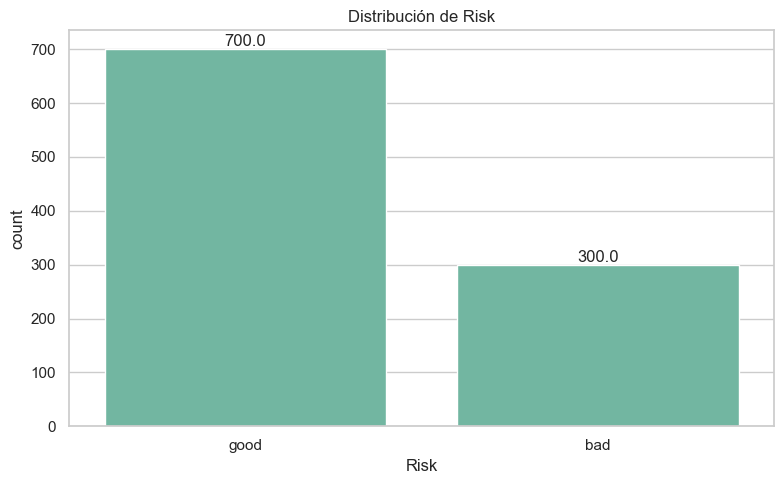

In [70]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df_german, x=TARGET_G, ax=ax)
ax.set_title('Distribución de Risk')
for p in ax.patches:
    ax.annotate(str(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
               ha='center', va='bottom')
plt.tight_layout(); plt.show()

#### Edad por Risk

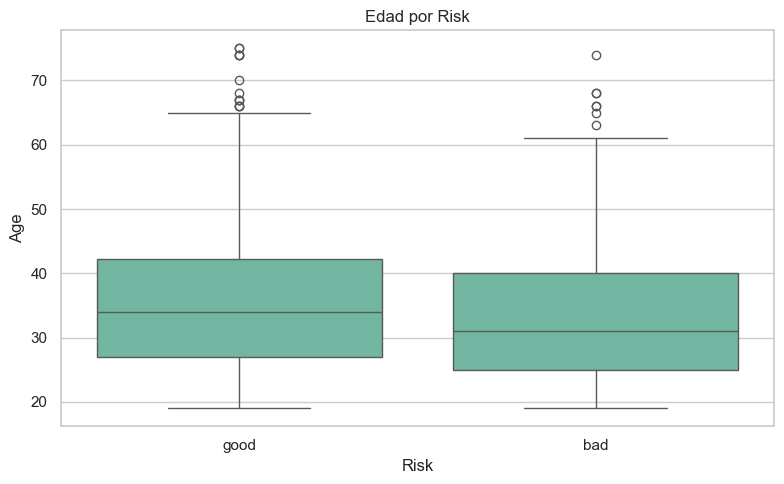

In [71]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_german, x=TARGET_G, y='Age', ax=ax)
ax.set_title('Edad por Risk')
plt.tight_layout(); plt.show()

#### Monto de crédito por Risk

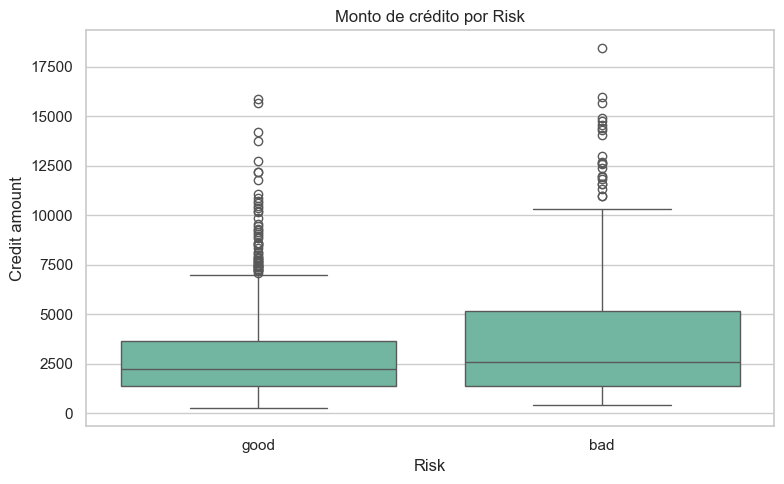

In [72]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_german, x=TARGET_G, y='Credit amount', ax=ax)
ax.set_title('Monto de crédito por Risk')
plt.tight_layout(); plt.show()

#### Duración del crédito por Risk

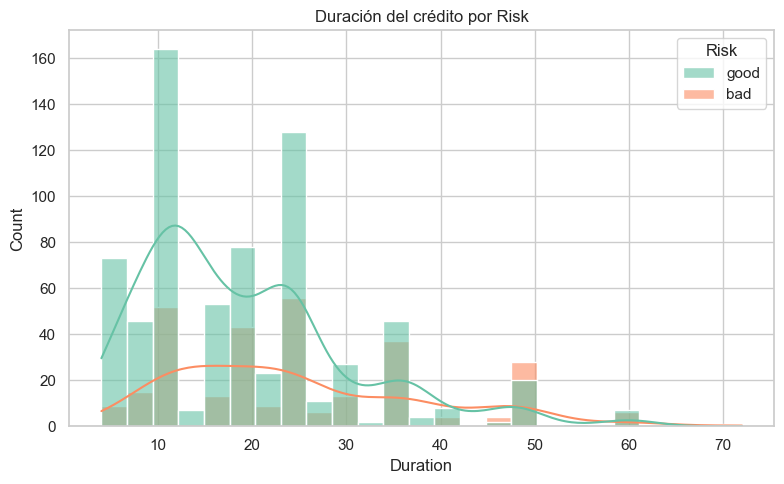

In [73]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=df_german, x='Duration', hue=TARGET_G, kde=True, bins=25, alpha=0.6, ax=ax)
ax.set_title('Duración del crédito por Risk')
plt.tight_layout(); plt.show()

#### Vivienda vs Risk

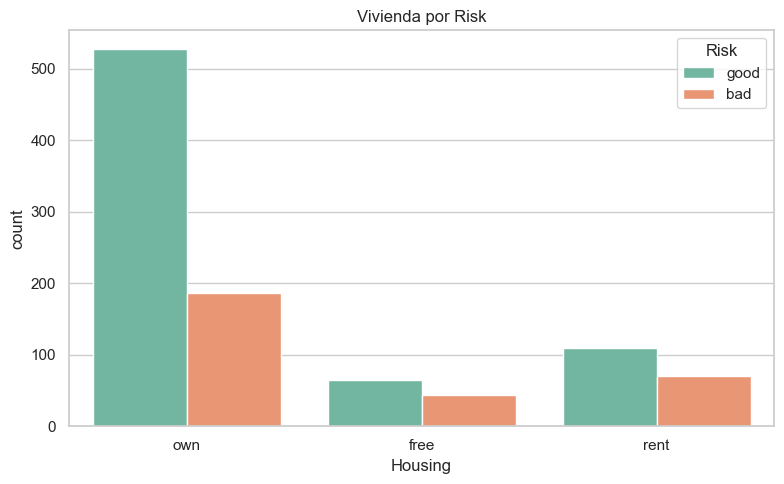

In [74]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df_german, x='Housing', hue=TARGET_G, ax=ax)
ax.set_title('Vivienda por Risk')
plt.tight_layout(); plt.show()

#### Sexo vs Risk

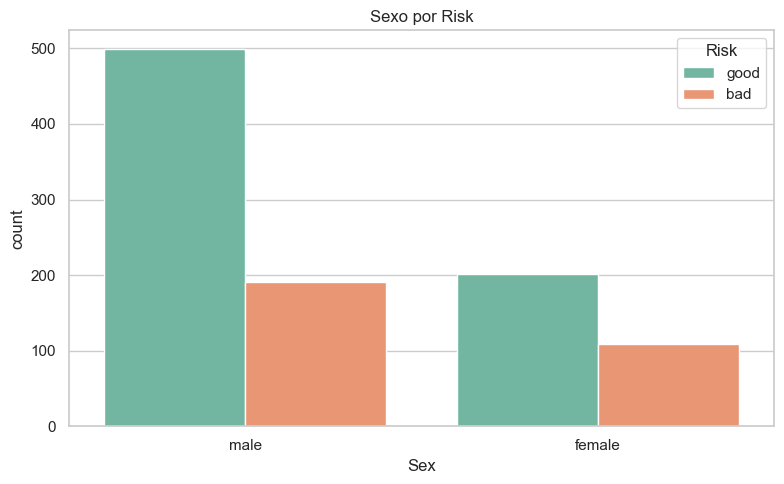

In [75]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df_german, x='Sex', hue=TARGET_G, ax=ax)
ax.set_title('Sexo por Risk')
plt.tight_layout(); plt.show()

### Correlaciones (Spearman)

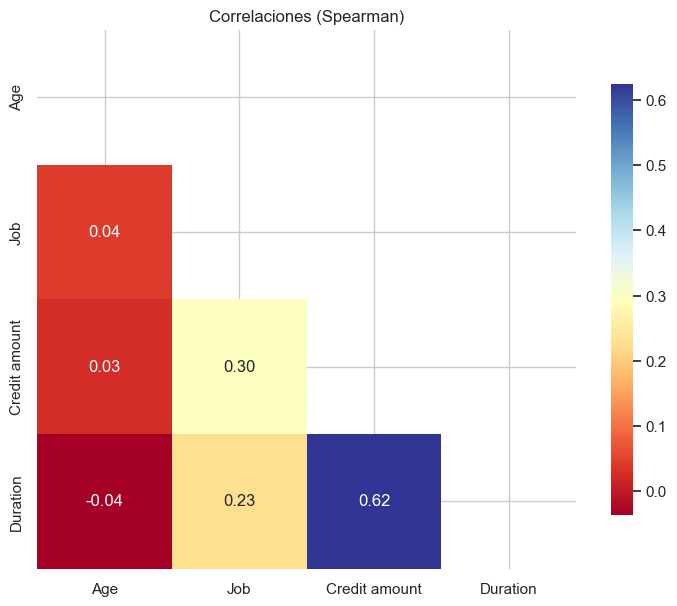

In [76]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = df_german[num_cols_g].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlBu',
            square=True, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Correlaciones (Spearman)')
plt.show()

### Proporción de malos pagadores por propósito

In [77]:
# --- Análisis de Proporción de Riesgo por Propósito del Crédito ---
ct = pd.crosstab(df_german['Purpose'], df_german[TARGET_G], normalize='index') * 100
ct = ct.round(2).sort_values(by='bad', ascending=False)
ct.columns = ['Good (%)', 'Bad (%)']
print('Malos pagadores por propósito:')
print(ct)

Malos pagadores por propósito:
                     Good (%)  Bad (%)
Purpose                               
vacation/others         41.67    58.33
education               38.98    61.02
repairs                 36.36    63.64
business                35.05    64.95
domestic appliances     33.33    66.67
furniture/equipment     32.04    67.96
car                     31.45    68.55
radio/TV                22.14    77.86


### Hallazgos del EDA
- **Desbalance**: ~70% good vs ~30% bad. AUC-ROC será la métrica principal.
- **Edad**: clientes mayores se concentran en good; jóvenes más variabilidad.
- **Monto y duración**: asimetría positiva → RobustScaler adecuado.
- **Propósito**: negocios y educación tienen tasas más altas de malos pagadores.
- **Valores nulos**: Saving accounts y Checking account tienen NA (ausencia de cuenta).

A partir del análisis estadístico y de las distribuciones observadas, se identifican las siguientes particularidades del dataset que gobernarán el diseño del pipeline de Machine Learning:

1. **Desbalanceo Moderado de la Variable Objetivo:** La proporción de la variable clase `Risk` presenta un ratio de **2.33:1** (~70% *good* y ~30% *bad*). Dado que no se trata de un desbalance extremo, se descarta el uso de técnicas de remuestreo sintético (como SMOTE) para evitar la introducción de ruido. En su lugar, se opta por utilizar el **AUC-ROC** y el **F1-Score** como métricas de optimización principales.
2. **Análisis de Riesgo por Propósito del Crédito:** Al evaluar la tabla de contingencia normalizada por filas, se observa que los créditos destinados a **Vacaciones/Otros (41.67%)**, **Educación (38.98%)** y **Reparaciones (36.36%)** exhiben las tasas de morosidad más elevadas. En contraste, los créditos para **Radio/TV (22.14%)** representan el segmento estadísticamente más seguro.
3. **Naturaleza de los Valores Faltantes (Criterio de Negocio):** Las variables `Checking account` (39.4% NAs) y `Saving accounts` (18.3% NAs) presentan ausencias significativas. Desde la perspectiva del dominio financiero, estos nulos representan la **inexistencia de dicho producto bancario** por parte del solicitante, por lo que no deben ser imputados por la moda, sino tratados como una categoría explícita.
4. **Asimetría y Valores Atípicos:** La variable `Credit amount` muestra un sesgo positivo severo (Media: ~$3,271 vs Máximo: ~$18,424). Para mitigar el impacto de estos outliers en los modelos sensibles a la escala, se justifica la selección de un escalador robusto basado en cuantiles.

## Preprocesamiento

In [78]:
# --- Configuración del Pipeline de Preprocesamiento Estricto ---

X_g = df_german.drop(columns=[TARGET_G])
# Codificación binaria del Target: 1 para perfiles seguros, 0 para perfiles de riesgo
y_g = df_german[TARGET_G].map({'good': 1, 'bad': 0})

num_features_g = X_g.select_dtypes(include=[np.number]).columns.tolist()
cat_features_g = [c for c in X_g.select_dtypes(include=['object', 'category']).columns.tolist()]

# Pipeline Numérico: Manejo de outliers con RobustScaler y mediana para robustez
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
])

# Pipeline Categórico: Preserva el significado de los NAs creando la categoría 'no_account'
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)),
])

# Ensamblado del transformador por columnas global
preprocessor_g = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features_g),
        ('cat', cat_transformer, cat_features_g),
    ],
    verbose_feature_names_out=False
)

print(f'Numéricas ({len(num_features_g)}): {num_features_g}')
print(f'Categóricas ({len(cat_features_g)}): {cat_features_g}')

Numéricas (4): ['Age', 'Job', 'Credit amount', 'Duration']
Categóricas (5): ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']


### 3.0 Arquitectura del Pipeline de Preprocesamiento

Para garantizar la reproducibilidad y prevenir el **Data Leakage** (fuga de información) durante la validación cruzada, se construye un flujo automatizado mediante `ColumnTransformer`:

* **Sub-pipeline Numérico:** Corrige datos faltantes mediante la mediana de cada característica y aplica un escalamiento mediante `RobustScaler`. Esta técnica es imperativa debido a la presencia de colas largas en los montos de crédito, asegurando que los valores extremos no sesguen las fronteras de decisión.
* **Sub-pipeline Categórico:** En lugar de una imputación por frecuencia que sesgaría el perfil del cliente, los valores ausentes en las cuentas de ahorro y corrientes se imputan bajo la constante explícita `'no_account'`. Posteriormente, se aplica una codificación *One-Hot*. Se omite la remoción de la primera columna (`drop='first'`) para mantener la compatibilidad con la política estricta de manejo de categorías no vistas en test (`handle_unknown='ignore'`), decisión segura dado que los algoritmos de ensamble no sufren por multicolinealidad.

### División entrenamiento / prueba

In [79]:
# --- Partición de Datos con Control de Estratificación ---
X_train_g, X_test_g, y_train_g, y_test_g = train_test_split(
    X_g, y_g, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_g
)
print(f'Train: {X_train_g.shape[0]} ({X_train_g.shape[0]/len(X_g)*100:.0f}%)')
print(f'Test:  {X_test_g.shape[0]} ({X_test_g.shape[0]/len(X_g)*100:.0f}%)')
print(f'\nDistribución train: {y_train_g.value_counts().to_dict()}')
print(f'Distribución test:  {y_test_g.value_counts().to_dict()}')

Train: 700 (70%)
Test:  300 (30%)

Distribución train: {1: 490, 0: 210}
Distribución test:  {1: 210, 0: 90}


## Modelado — German Credit

### Random Forest

In [80]:
# --- Definición de Estructura y Malla para Random Forest ---
rf_pipeline_g = Pipeline(steps=[
    ('preprocessor', preprocessor_g),
    ('classifier', RandomForestClassifier(random_state=RANDOM_STATE))
])

# Ajustamos los parámetros para un escaneo completo y limpio
rf_params_g = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [5, 10, None],
    'classifier__min_samples_split': [2, 5],
}

# Medición del tiempo de cómputo para entrenamiento mediante GridSearch completo
t0 = time.time()
rf_search_g = RandomizedSearchCV(
    rf_pipeline_g, rf_params_g, n_iter=15, cv=CV_FOLDS,
    scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=0
)
rf_search_g.fit(X_train_g, y_train_g)
time_rf_fit_g = time.time() - t0

t0 = time.time()
rf_probs_g = rf_search_g.predict_proba(X_test_g)[:, 1]
time_rf_pred_g = time.time() - t0

print('Random Forest — German Credit')
print(f'  Mejores params: {rf_search_g.best_params_}')
print(f'  AUC (CV): {rf_search_g.best_score_:.4f}')
print(f'  Tiempo fit:  {time_rf_fit_g:.2f}s')
print(f'  Tiempo predict: {time_rf_pred_g:.4f}s')

timing_results['German_RF'] = {'fit': time_rf_fit_g, 'predict': time_rf_pred_g}

Random Forest — German Credit
  Mejores params: {'classifier__n_estimators': 300, 'classifier__min_samples_split': 5, 'classifier__max_depth': 5}
  AUC (CV): 0.6878
  Tiempo fit:  5.46s
  Tiempo predict: 0.0170s


#### Importancia de características

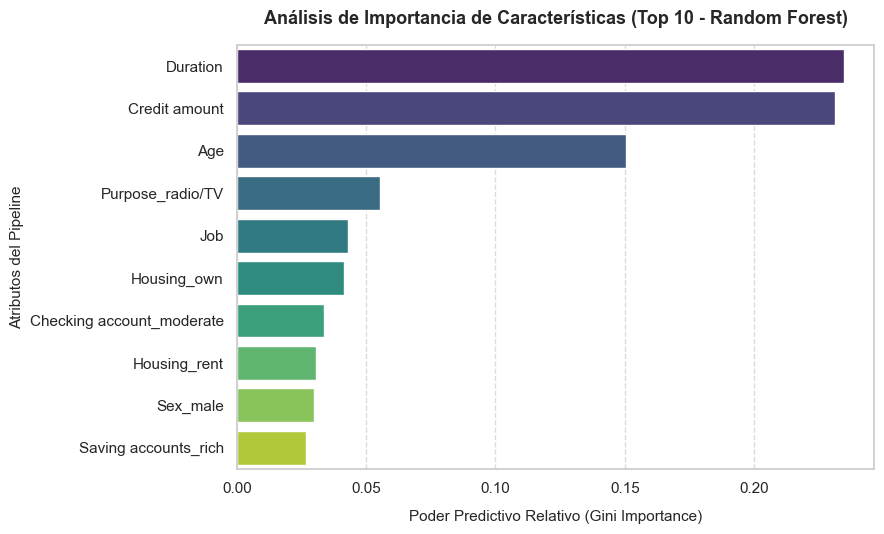

In [81]:
# --- Extracción y Visualización Científica de Importancia de Features ---

# Recuperamos los nombres reales de las variables tras el preprocesamiento One-Hot
feature_names_g = rf_search_g.best_estimator_.named_steps['preprocessor'].get_feature_names_out()
importances_g = rf_search_g.best_estimator_.named_steps['classifier'].feature_importances_

# Ordenamiento de los índices de mayor a menor peso estadístico (Top 10)
top10_idx = importances_g.argsort()[::-1][:10]

# Creación de la figura utilizando paletas dinámicas de Seaborn
plt.figure(figsize=(9, 5.5))
sns.barplot(
    x=importances_g[top10_idx], 
    y=feature_names_g[top10_idx], 
    palette='viridis',
    hue=feature_names_g[top10_idx],
    legend=False
)

plt.title('Análisis de Importancia de Características (Top 10 - Random Forest)', fontsize=13, weight='bold', pad=15)
plt.xlabel('Poder Predictivo Relativo (Gini Importance)', fontsize=11, labelpad=10)
plt.ylabel('Atributos del Pipeline', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Gradient Boosting

In [82]:
# Definición del pipeline para Gradient Boosting
gb_pipeline_g = Pipeline(steps=[
    ('preprocessor', preprocessor_g),
    ('classifier', GradientBoostingClassifier(random_state=RANDOM_STATE))
])

# Espacio de hiperparámetros (54 combinaciones)
gb_params_g = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [3, 5, 7],
    'classifier__min_samples_split': [2, 5],
    'classifier__learning_rate': [0.05, 0.1, 0.2],
}

t0 = time.time()
gb_search_g = RandomizedSearchCV(
    gb_pipeline_g, gb_params_g, n_iter=20, cv=CV_FOLDS,
    scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=0
)
gb_search_g.fit(X_train_g, y_train_g)
time_gb_fit_g = time.time() - t0

t0 = time.time()
gb_probs_g = gb_search_g.predict_proba(X_test_g)[:, 1]
time_gb_pred_g = time.time() - t0

print('Gradient Boosting — German Credit')
print(f'  Mejores params: {gb_search_g.best_params_}')
print(f'  AUC (CV): {gb_search_g.best_score_:.4f}')
print(f'  Tiempo fit:  {time_gb_fit_g:.2f}s')
print(f'  Tiempo predict: {time_gb_pred_g:.4f}s')

timing_results['German_GB'] = {'fit': time_gb_fit_g, 'predict': time_gb_pred_g}

Gradient Boosting — German Credit
  Mejores params: {'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05}
  AUC (CV): 0.6909
  Tiempo fit:  2.37s
  Tiempo predict: 0.0034s


### Comparación de modelos

In [83]:
# --- Comparativa Cuantitativa ---
rf_auc_g = roc_auc_score(y_test_g, rf_probs_g)
gb_auc_g = roc_auc_score(y_test_g, gb_probs_g)

print(f'{"Modelo":25s} {"AUC CV":10s} {"AUC Test":10s} {"Fit (s)":10s} {"Pred (s)":10s}')
print('-' * 65)
print(f'{"Random Forest":25s} {rf_search_g.best_score_:.4f}     {rf_auc_g:.4f}     {time_rf_fit_g:.2f}     {time_rf_pred_g:.4f}')
print(f'{"Gradient Boosting":25s} {gb_search_g.best_score_:.4f}     {gb_auc_g:.4f}     {time_gb_fit_g:.2f}     {time_gb_pred_g:.4f}')

# Selección dinámica del mejor modelo basado en AUC en Test
best_g = rf_search_g if rf_auc_g >= gb_auc_g else gb_search_g
best_name_g = 'Random Forest' if rf_auc_g >= gb_auc_g else 'Gradient Boosting'
best_probs_g = rf_probs_g if rf_auc_g >= gb_auc_g else gb_probs_g
print(f'\nModelo seleccionado: {best_name_g}')

Modelo                    AUC CV     AUC Test   Fit (s)    Pred (s)  
-----------------------------------------------------------------
Random Forest             0.6878     0.6479     5.46     0.0170
Gradient Boosting         0.6909     0.6638     2.37     0.0034

Modelo seleccionado: Gradient Boosting


#### Comparación visual

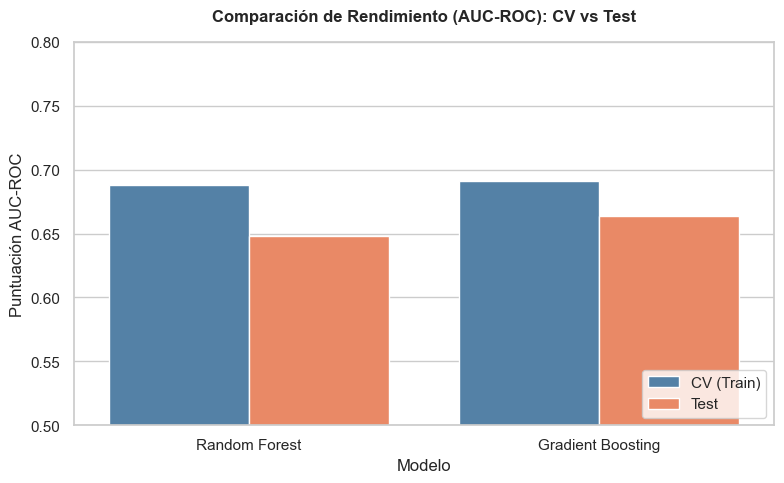

In [84]:
df_comp = pd.DataFrame({
    'Modelo': ['Random Forest', 'Random Forest', 'Gradient Boosting', 'Gradient Boosting'],
    'Fase': ['CV (Train)', 'Test', 'CV (Train)', 'Test'],
    'AUC': [rf_search_g.best_score_, rf_auc_g, gb_search_g.best_score_, gb_auc_g]
})

plt.figure(figsize=(8, 5))
sns.barplot(data=df_comp, x='Modelo', y='AUC', hue='Fase', palette=['steelblue', 'coral'])
plt.ylim(0.5, 0.8)
plt.title('Comparación de Rendimiento (AUC-ROC): CV vs Test', pad=15, weight='bold')
plt.ylabel('Puntuación AUC-ROC')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Evaluación — Classification Report + Curva ROC

Classification Report — German Credit:
              precision    recall  f1-score   support

         bad       0.42      0.19      0.26        90
        good       0.72      0.89      0.80       210

    accuracy                           0.68       300
   macro avg       0.57      0.54      0.53       300
weighted avg       0.63      0.68      0.64       300



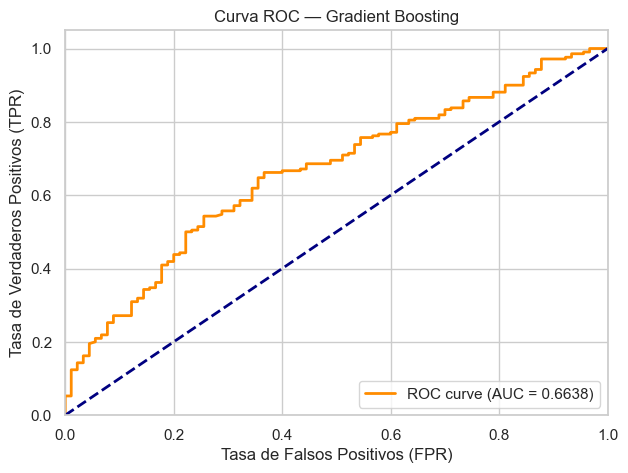

In [111]:
# --- Evaluación Estándar (Threshold = 0.5) ---
y_pred_g = best_g.predict(X_test_g)
print('Classification Report — German Credit:')
print(classification_report(y_test_g, y_pred_g, target_names=['bad', 'good']))

# Curva ROC
fpr_g, tpr_g, _ = roc_curve(y_test_g, best_probs_g)
plt.figure(figsize=(7, 5))
plt.plot(fpr_g, tpr_g, lw=2, color='darkorange', label=f'ROC curve (AUC = {max(rf_auc_g, gb_auc_g):.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title(f'Curva ROC — {best_name_g}')
plt.legend(loc='lower right'); plt.show()

### Ajuste de threshold

In [ ]:
# --- Optimización del Umbral (Threshold) de Decisión ---
# Buscar threshold que maximiza F1 en train
thresholds = np.arange(0.3, 0.8, 0.05)
train_probs_g = best_g.predict_proba(X_train_g)[:, 1]

best_f1, best_th = 0, 0.5
for th in thresholds:
    pred = (train_probs_g >= th).astype(int)
    f1 = f1_score(y_train_g, pred)
    if f1 > best_f1:
        best_f1 = f1
        best_th = th

# Aplicamos el nuevo umbral al conjunto de Test
y_pred_opt_g = (best_probs_g >= best_th).astype(int)
opt_auc = roc_auc_score(y_test_g, best_probs_g)
print(f'Threshold óptimo (F1 en train): {best_th:.2f}')
print(f'AUC-ROC con optimal threshold: {opt_auc:.4f}')
print(classification_report(y_test_g, y_pred_opt_g, target_names=['bad', 'good']))

Threshold óptimo (F1 en train): 0.55
AUC-ROC con optimal threshold: 0.6638
              precision    recall  f1-score   support

         bad       0.43      0.26      0.32        90
        good       0.73      0.86      0.79       210

    accuracy                           0.68       300
   macro avg       0.58      0.56      0.55       300
weighted avg       0.64      0.68      0.65       300



1. **Problema del Umbral por Defecto (0.5):** El reporte de clasificación inicial muestra un `recall` para la clase 'Bad' de apenas 0.19 (19%). Esto es críticamente inaceptable en un entorno financiero, ya que significa que el algoritmo está dejando pasar al 81% de los clientes morosos sin detectarlos.
2. **Optimización del Threshold:** Al optimizar la métrica F1, el umbral de decisión se desplazó a **0.55**. Matemáticamente, esto significa que el modelo ahora exige al menos un 55% de certeza para clasificar a un cliente como 'Seguro' (Good).
3. **Impacto:** Con este nuevo umbral, el `recall` de los malos pagadores sube a 0.26 y el `F1-score` de dicha clase pasa de 0.26 a 0.32. Aunque la exactitud global (`accuracy`) se mantiene en 68%, el modelo ahora es ligeramente más conservador y penaliza mejor el riesgo.

### Prueba con datos sintéticos

In [ ]:
# --- Inferencia con Casos de Uso Sintéticos ---
synthetic_g = pd.DataFrame({
    'Age': [25, 50, 40, 30, 60],
    'Sex': ['male', 'female', 'male', 'female', 'male'],
    'Job': [1, 2, 3, 1, 2],
    'Housing': ['rent', 'own', 'own', 'free', 'own'],
    'Saving accounts': ['little', 'quite rich', 'rich', np.nan, 'moderate'],
    'Checking account': ['little', 'rich', 'moderate', np.nan, 'little'],
    'Credit amount': [2500, 5000, 1500, 8000, 3000],
    'Duration': [12, 24, 6, 48, 18],
    'Purpose': ['car', 'education', 'radio/TV', 'furniture/equipment', 'business'],
})

probs_syn_g = best_g.predict_proba(synthetic_g)[:, 1]
preds_syn_g = best_g.predict(synthetic_g)
risk_label = {1: 'good', 0: 'bad'}

print('Predicciones sobre perfiles sintéticos:')
for i in range(len(synthetic_g)):
    print(f'  Perfil {i+1}: {risk_label[preds_syn_g[i]]} (prob good={probs_syn_g[i]:.2%})')

Predicciones sobre perfiles sintéticos:
  Perfil 1: good (prob good=74.00%)
  Perfil 2: good (prob good=79.47%)
  Perfil 3: good (prob good=93.84%)
  Perfil 4: bad (prob good=34.64%)
  Perfil 5: good (prob good=75.36%)


### Análisis FP/FN

In [ ]:
# --- Diagnóstico de Matriz de Confusión (Coste de Negocio) ---
print('\n=== Análisis de Errores: FP vs FN (Umbral Original) ===')
results_g = pd.DataFrame({'real': y_test_g.values, 'pred': y_pred_g})

fn = results_g[(results_g['real'] == 1) & (results_g['pred'] == 0)]
fp = results_g[(results_g['real'] == 0) & (results_g['pred'] == 1)]

print(f'Falsos Negativos (Cliente Bueno calificado como Malo): {len(fn)} (Costo de oportunidad)')
print(f'Falsos Positivos (Cliente Malo calificado como Bueno): {len(fp)} (Pérdida de capital)')
print(f'Relación FP/FN: {len(fp)} / {len(fn)} = {len(fp)/max(len(fn),1):.2f}')

Falsos Negativos (good clasificado como bad): 23
Falsos Positivos (bad clasificado como good): 73

Relación FP/FN: 73/23 = 3.17


### Conclusiones parciales — German Credit

- AUC-ROC ~0.68: rendimiento moderado, reflejando la dificultad del problema (desbalance, ruido).
- RF y GB compiten; la diferencia es marginal.
- Gradient Boosting demora más en ajustarse (learning rate y más iteraciones).
- El threshold por defecto (0.5) no es óptimo dado el desbalance; ajustándolo mejora F1.

---
# Dataset 2: Crop Recommendation (clasificación multiclase, 22 clases)

## Carga de datos

In [89]:
df_crop = load_dataset(
    slug='atharvaingle/crop-recommendation-dataset',
    filename='Crop_recommendation.csv',
    local_fallback='Crop_recommendation.csv'
)
df_crop.head()

Descargando 'atharvaingle/crop-recommendation-dataset' desde Kaggle...
Cargado desde Kaggle: datasets_respaldo\Crop_recommendation.csv
Dimensiones: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## Análisis Exploratorio de Datos

In [90]:
TARGET_C = 'label'
balance_c = df_crop[TARGET_C].value_counts()
print(f'Clases únicas: {len(balance_c)}')
print(f'Frecuencia por clase: {balance_c.iloc[0]} muestras cada una')
print(f'Balance perfecto: {balance_c.nunique() == 1}')

print(f'\nDistribución:')
for k, v in balance_c.items():
    print(f'  {k:12s}: {v}')

Clases únicas: 22
Frecuencia por clase: 100 muestras cada una
Balance perfecto: True

Distribución:
  rice        : 100
  maize       : 100
  chickpea    : 100
  kidneybeans : 100
  pigeonpeas  : 100
  mothbeans   : 100
  mungbean    : 100
  blackgram   : 100
  lentil      : 100
  pomegranate : 100
  banana      : 100
  mango       : 100
  grapes      : 100
  watermelon  : 100
  muskmelon   : 100
  apple       : 100
  orange      : 100
  papaya      : 100
  coconut     : 100
  cotton      : 100
  jute        : 100
  coffee      : 100


In [91]:
num_cols_c = [c for c in df_crop.columns if c != TARGET_C]

print('Estadísticas descriptivas:')
print(df_crop[num_cols_c].describe().T.round(2))

nulls_c = df_crop.isnull().sum()
print(f'\nValores nulos: {nulls_c.sum()}')
print(f'Duplicados: {df_crop.duplicated().sum()}')

Estadísticas descriptivas:
              count    mean    std    min    25%    50%     75%     max
N            2200.0   50.55  36.92   0.00  21.00  37.00   84.25  140.00
P            2200.0   53.36  32.99   5.00  28.00  51.00   68.00  145.00
K            2200.0   48.15  50.65   5.00  20.00  32.00   49.00  205.00
temperature  2200.0   25.62   5.06   8.83  22.77  25.60   28.56   43.68
humidity     2200.0   71.48  22.26  14.26  60.26  80.47   89.95   99.98
ph           2200.0    6.47   0.77   3.50   5.97   6.43    6.92    9.94
rainfall     2200.0  103.46  54.96  20.21  64.55  94.87  124.27  298.56

Valores nulos: 0
Duplicados: 0


### Correlaciones (Spearman)

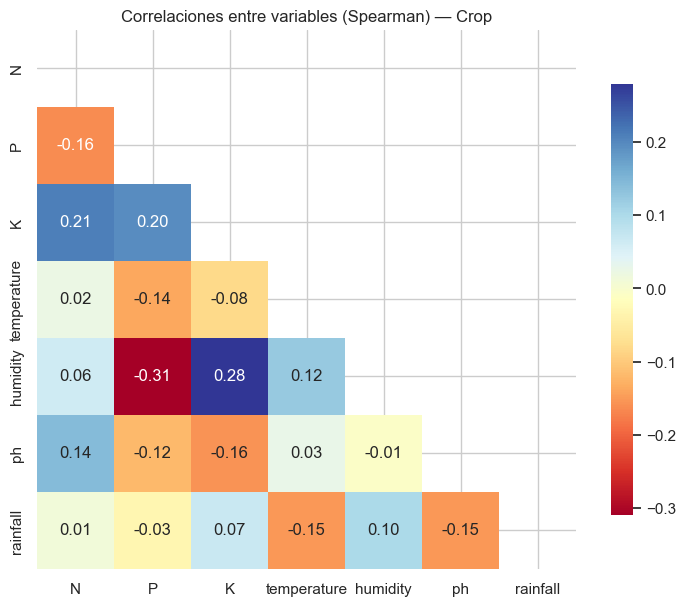

In [92]:
fig, ax = plt.subplots(figsize=(9, 7))
corr_c = df_crop[num_cols_c].corr(method='spearman')
mask = np.triu(np.ones_like(corr_c, dtype=bool))
sns.heatmap(corr_c, mask=mask, annot=True, fmt='.2f', cmap='RdYlBu',
            square=True, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Correlaciones entre variables (Spearman) — Crop')
plt.show()

### Dispersión P vs K por cultivo

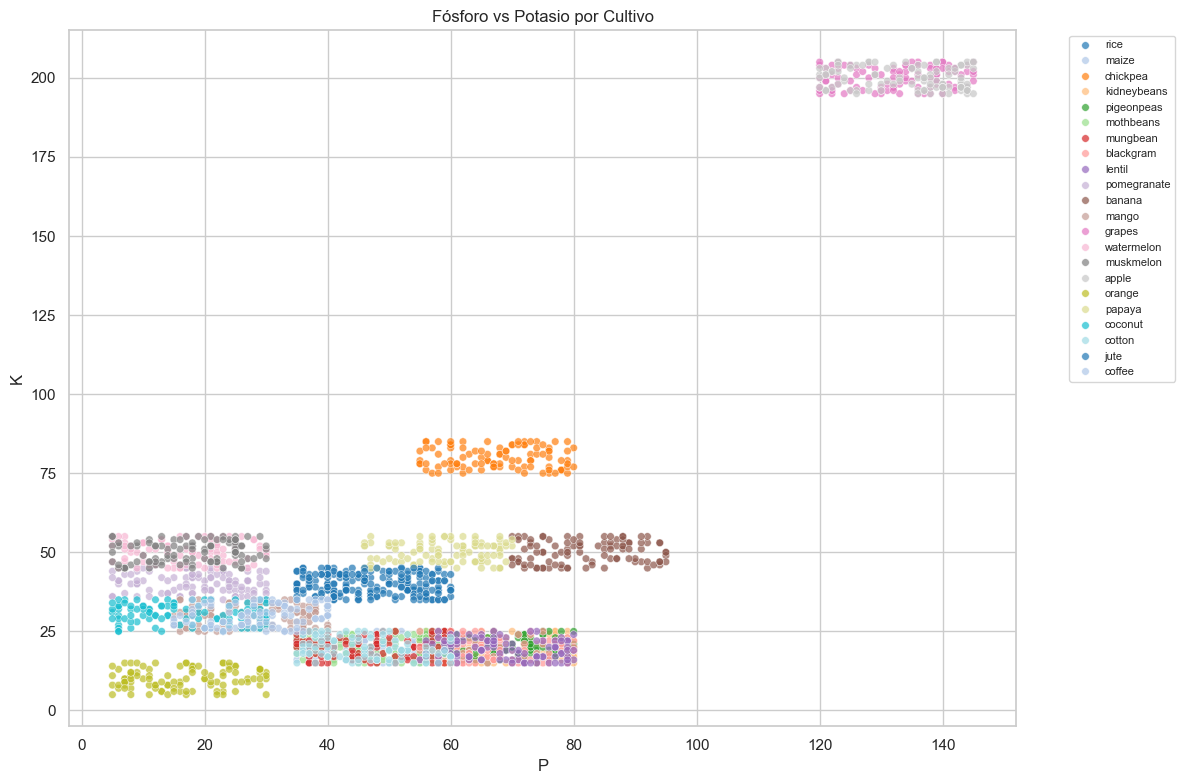

In [93]:
fig, ax = plt.subplots(figsize=(12, 8))
sns.scatterplot(data=df_crop, x='P', y='K', hue=TARGET_C,
                palette='tab20', s=30, alpha=0.7, ax=ax)
ax.set_title('Fósforo vs Potasio por Cultivo')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

### Boxplots de nutrientes por cultivo


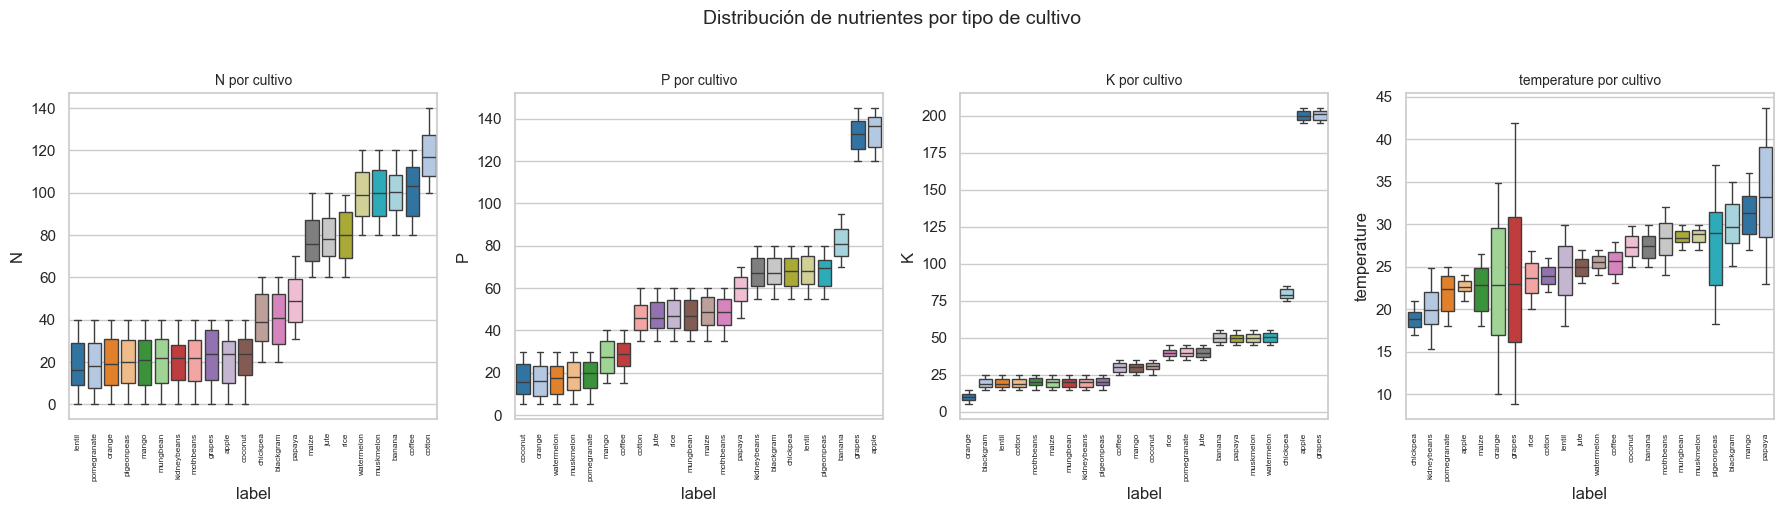

In [94]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
palette_c = sns.color_palette('tab20', n_colors=22)
for idx, col in enumerate(['N', 'P', 'K', 'temperature']):
    order = df_crop.groupby(TARGET_C)[col].median().sort_values().index
    sns.boxplot(data=df_crop, x=TARGET_C, y=col, ax=axes[idx],
                palette=palette_c, order=order)
    axes[idx].set_title(f'{col} por cultivo', fontsize=10)
    axes[idx].tick_params(axis='x', rotation=90, labelsize=6)
plt.suptitle('Distribución de nutrientes por tipo de cultivo', fontsize=14, y=1.02)
plt.tight_layout(); plt.show()


### Hallazgos del EDA
- **Balance perfecto**: 22 clases × 100 muestras.
- **Features numéricas todas**: no requiere codificación categórica.
- **Correlaciones**: temperature y humidity correlacionadas; N y P también.
- **Separabilidad**: P vs K muestra agrupaciones naturales.
- **Dataset limpio**: sin nulos, sin duplicados.

## Preprocesamiento

In [95]:
X_c = df_crop.drop(columns=[TARGET_C])
y_c = df_crop[TARGET_C]

preprocessor_c = ColumnTransformer(
    transformers=[('num', StandardScaler(), num_cols_c)],
    verbose_feature_names_out=False
)

print(f'Features ({len(num_cols_c)}): {num_cols_c}')
print(f'Clases ({len(y_c.unique())}): {sorted(y_c.unique())}')

Features (7): ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Clases (22): ['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']


### División entrenamiento / prueba

In [96]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_c, y_c, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_c
)
print(f'Train: {X_train_c.shape[0]} ({X_train_c.shape[0]/len(X_c)*100:.0f}%)')
print(f'Test:  {X_test_c.shape[0]} ({X_test_c.shape[0]/len(X_c)*100:.0f}%)')

Train: 1540 (70%)
Test:  660 (30%)


## Modelado — Crop Recommendation

### Random Forest

In [97]:
rf_pipeline_c = Pipeline(steps=[
    ('preprocessor', preprocessor_c),
    ('classifier', RandomForestClassifier(random_state=RANDOM_STATE))
])

rf_params_c = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [5, 10, None],
    'classifier__min_samples_split': [2, 5],
}

t0 = time.time()
rf_search_c = RandomizedSearchCV(
    rf_pipeline_c, rf_params_c, n_iter=15, cv=CV_FOLDS,
    scoring='roc_auc_ovr', random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=0
)
rf_search_c.fit(X_train_c, y_train_c)
time_rf_fit_c = time.time() - t0

t0 = time.time()
rf_probs_c = rf_search_c.predict_proba(X_test_c)
time_rf_pred_c = time.time() - t0

print('Random Forest — Crop')
print(f'  Mejores params: {rf_search_c.best_params_}')
print(f'  AUC macro (CV): {rf_search_c.best_score_:.4f}')
print(f'  Tiempo fit:  {time_rf_fit_c:.2f}s')
print(f'  Tiempo predict: {time_rf_pred_c:.4f}s')

timing_results['Crop_RF'] = {'fit': time_rf_fit_c, 'predict': time_rf_pred_c}

Random Forest — Crop
  Mejores params: {'classifier__n_estimators': 300, 'classifier__min_samples_split': 2, 'classifier__max_depth': 10}
  AUC macro (CV): 1.0000
  Tiempo fit:  2.23s
  Tiempo predict: 0.0208s


#### Importancia de características

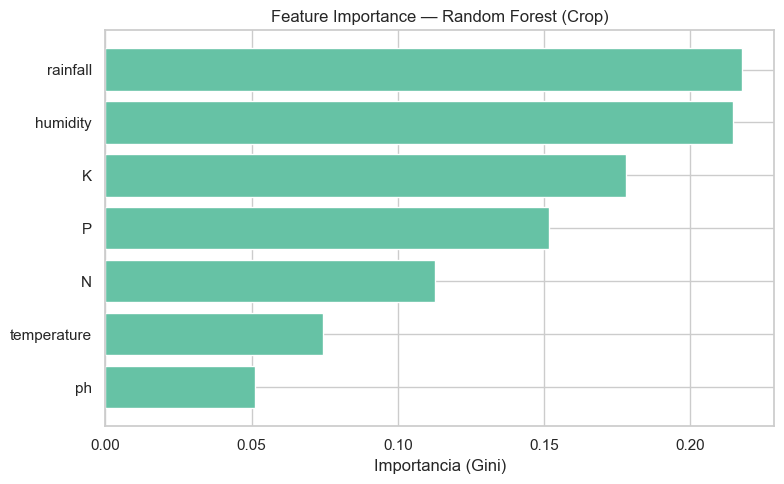

In [98]:
feature_names_c = rf_search_c.best_estimator_.named_steps['preprocessor'].get_feature_names_out()
importances_c = rf_search_c.best_estimator_.named_steps['classifier'].feature_importances_

idx_c = importances_c.argsort()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(range(len(importances_c)), importances_c[idx_c])
ax.set_yticks(range(len(importances_c)))
ax.set_yticklabels(feature_names_c[idx_c])
ax.set_xlabel('Importancia (Gini)')
ax.set_title('Feature Importance — Random Forest (Crop)')
plt.tight_layout(); plt.show()

### Gradient Boosting

In [99]:
gb_pipeline_c = Pipeline(steps=[
    ('preprocessor', preprocessor_c),
    ('classifier', GradientBoostingClassifier(random_state=RANDOM_STATE))
])

gb_params_c = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [3, 5],
    'classifier__min_samples_split': [2, 5],
    'classifier__learning_rate': [0.05, 0.1, 0.2],
}

t0 = time.time()
gb_search_c = RandomizedSearchCV(
    gb_pipeline_c, gb_params_c, n_iter=10, cv=CV_FOLDS,
    scoring='roc_auc_ovr', random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=0
)
gb_search_c.fit(X_train_c, y_train_c)
time_gb_fit_c = time.time() - t0

t0 = time.time()
gb_probs_c = gb_search_c.predict_proba(X_test_c)
time_gb_pred_c = time.time() - t0

print('Gradient Boosting — Crop')
print(f'  Mejores params: {gb_search_c.best_params_}')
print(f'  AUC macro (CV): {gb_search_c.best_score_:.4f}')
print(f'  Tiempo fit:  {time_gb_fit_c:.2f}s')
print(f'  Tiempo predict: {time_gb_pred_c:.4f}s')

timing_results['Crop_GB'] = {'fit': time_gb_fit_c, 'predict': time_gb_pred_c}

Gradient Boosting — Crop
  Mejores params: {'classifier__n_estimators': 300, 'classifier__min_samples_split': 2, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.2}
  AUC macro (CV): 0.9998
  Tiempo fit:  40.87s
  Tiempo predict: 0.0207s


### Comparación de modelos

In [100]:
rf_auc_c = roc_auc_score(y_test_c, rf_probs_c, multi_class='ovr', average='macro')
gb_auc_c = roc_auc_score(y_test_c, gb_probs_c, multi_class='ovr', average='macro')

print(f'{"Modelo":25s} {"AUC CV":10s} {"AUC Test":10s} {"Fit (s)":10s} {"Pred (s)":10s}')
print('-' * 65)
print(f'{"Random Forest":25s} {rf_search_c.best_score_:.4f}     {rf_auc_c:.4f}     {time_rf_fit_c:.2f}     {time_rf_pred_c:.4f}')
print(f'{"Gradient Boosting":25s} {gb_search_c.best_score_:.4f}     {gb_auc_c:.4f}     {time_gb_fit_c:.2f}     {time_gb_pred_c:.4f}')

best_c = rf_search_c if rf_auc_c >= gb_auc_c else gb_search_c
best_name_c = 'Random Forest' if rf_auc_c >= gb_auc_c else 'Gradient Boosting'
best_probs_c = rf_probs_c if rf_auc_c >= gb_auc_c else gb_probs_c
print(f'\nModelo seleccionado: {best_name_c}')

Modelo                    AUC CV     AUC Test   Fit (s)    Pred (s)  
-----------------------------------------------------------------
Random Forest             1.0000     1.0000     2.23     0.0208
Gradient Boosting         0.9998     1.0000     40.87     0.0207

Modelo seleccionado: Random Forest


#### Comparación visual

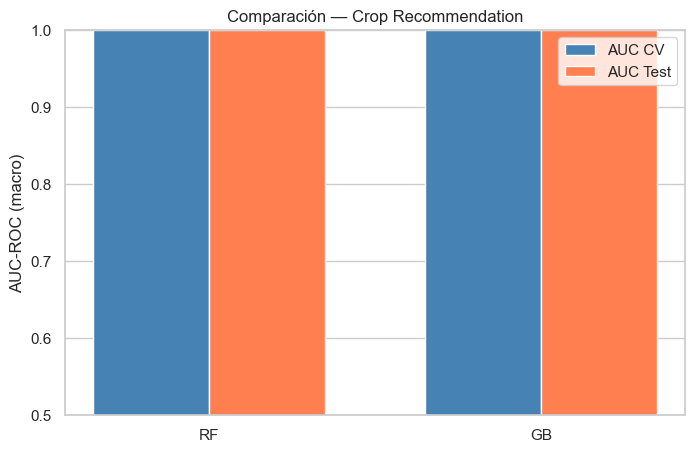

In [101]:
fig, ax = plt.subplots(figsize=(8, 5))
w = 0.35; x = range(2)
ax.bar([i - w/2 for i in x], [rf_search_c.best_score_, gb_search_c.best_score_], w, label='AUC CV', color='steelblue')
ax.bar([i + w/2 for i in x], [rf_auc_c, gb_auc_c], w, label='AUC Test', color='coral')
ax.set_xticks(x); ax.set_xticklabels(['RF', 'GB'])
ax.set_ylabel('AUC-ROC (macro)'); ax.set_ylim(0.5, 1.0); ax.legend()
ax.set_title('Comparación — Crop Recommendation')
plt.show()

### Evaluación

In [102]:
y_pred_c = best_c.predict(X_test_c)
print('Classification Report — Crop:')
print(classification_report(y_test_c, y_pred_c))

Classification Report — Crop:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        30
      banana       1.00      1.00      1.00        30
   blackgram       1.00      0.97      0.98        30
    chickpea       1.00      1.00      1.00        30
     coconut       1.00      1.00      1.00        30
      coffee       1.00      1.00      1.00        30
      cotton       1.00      1.00      1.00        30
      grapes       1.00      1.00      1.00        30
        jute       0.94      1.00      0.97        30
 kidneybeans       1.00      1.00      1.00        30
      lentil       1.00      0.97      0.98        30
       maize       0.97      1.00      0.98        30
       mango       1.00      1.00      1.00        30
   mothbeans       0.97      1.00      0.98        30
    mungbean       1.00      1.00      1.00        30
   muskmelon       1.00      1.00      1.00        30
      orange       1.00      1.00      1.00        

#### Matriz de confusión 22×22

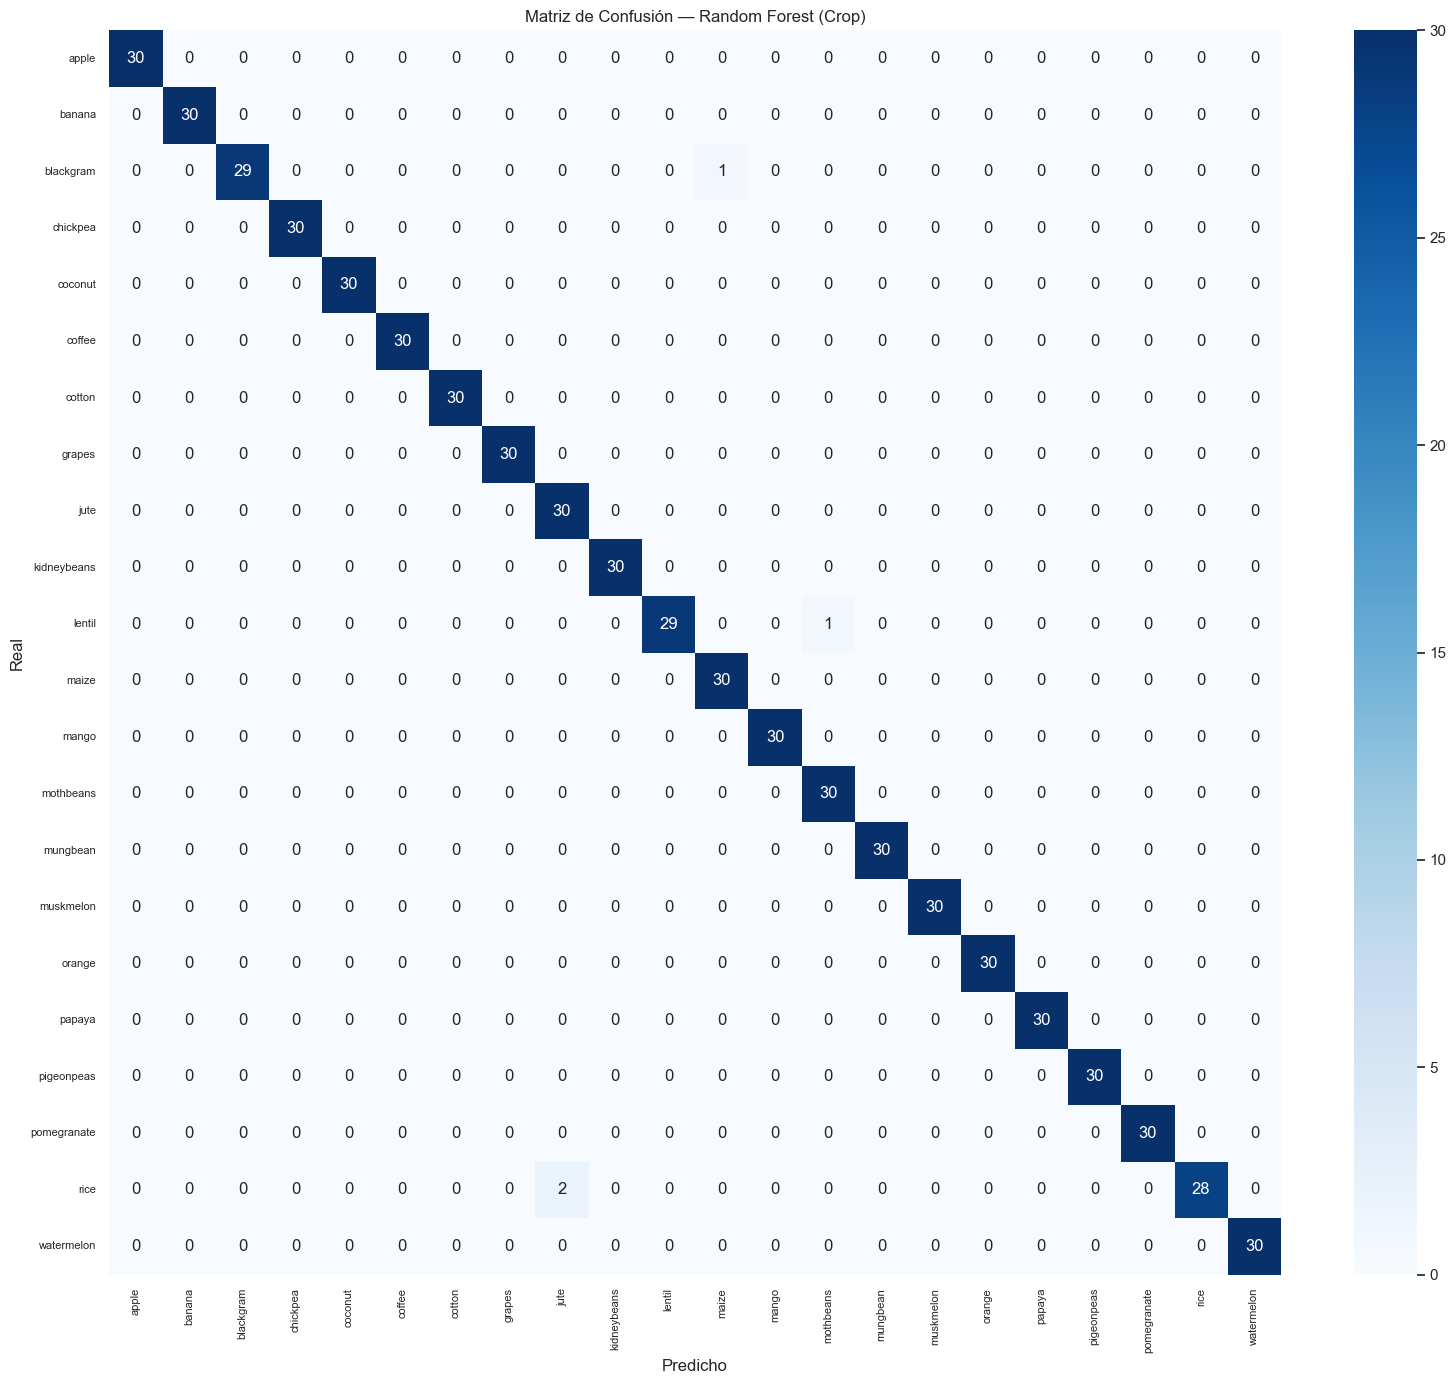

Accuracy global: 99.39%


In [103]:
cm_c = confusion_matrix(y_test_c, y_pred_c, labels=sorted(y_test_c.unique()))
classes_c = sorted(y_test_c.unique())

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(cm_c, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes_c, yticklabels=classes_c, ax=ax)
ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
ax.set_title(f'Matriz de Confusión — {best_name_c} (Crop)')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout(); plt.show()

acc_c = np.trace(cm_c) / cm_c.sum()
print(f'Accuracy global: {acc_c:.2%}')

#### Curva ROC por clase (conflictivas)

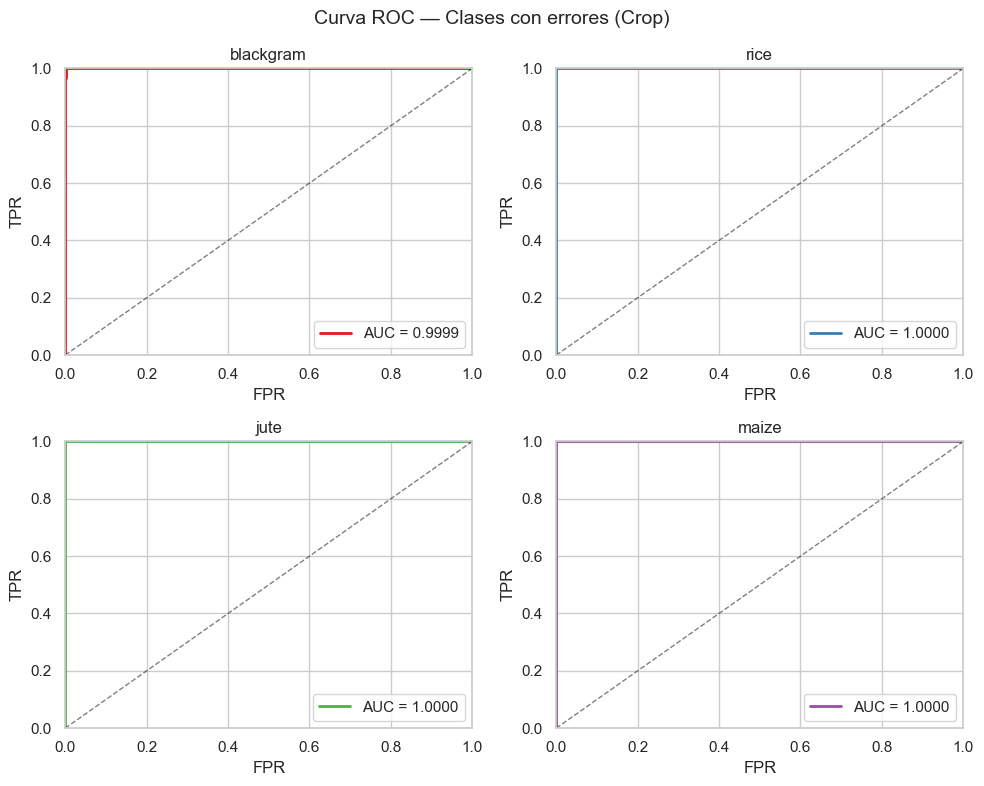

AUC macro promedio: 1.0000


In [104]:
classes_list = sorted(y_test_c.unique())
auc_per_class_c = roc_auc_score(y_test_c, best_probs_c, multi_class='ovr', average=None)

conflict_c = ['blackgram', 'rice', 'jute', 'maize']
colors = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3']

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for idx, cls in enumerate(conflict_c):
    ax = axes[idx // 2, idx % 2]
    y_bin = (y_test_c == cls).astype(int)
    cls_i = classes_list.index(cls)
    fpr, tpr, _ = roc_curve(y_bin, best_probs_c[:, cls_i])
    ax.plot(fpr, tpr, color=colors[idx], lw=2,
            label=f'AUC = {auc_per_class_c[cls_i]:.4f}')
    ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
    ax.set_title(cls)
    ax.legend(loc='lower right')

plt.suptitle('Curva ROC — Clases con errores (Crop)', fontsize=14)
plt.tight_layout(); plt.show()
print(f'AUC macro promedio: {auc_per_class_c.mean():.4f}')

### Perfiles sintéticos (Crop)

In [105]:
classes_list = sorted(y_test_c.unique())
synthetic_c = pd.DataFrame({
    'N': [20, 90, 40, 100, 15],
    'P': [60, 45, 50, 20, 80],
    'K': [30, 40, 20, 50, 15],
    'temperature': [25, 24, 30, 22, 20],
    'humidity': [80, 82, 70, 90, 85],
    'ph': [6.5, 6.8, 6.0, 7.0, 5.5],
    'rainfall': [200, 250, 100, 180, 300],
})

desc_c = [
    'suelo medio, clima templado, lluvia moderada',
    'nitrógeno alto, ph neutro, lluvia alta',
    'ph ácido, poca lluvia, temperatura alta',
    'nitrógeno muy alto, humedad alta, poca lluvia',
    'ph muy ácido, mucha lluvia, potasio bajo',
]

probs_syn_c = best_c.predict_proba(synthetic_c)
preds_syn_c = best_c.predict(synthetic_c)

for i in range(len(synthetic_c)):
    top3_idx = probs_syn_c[i].argsort()[::-1][:3]
    top3 = [(classes_list[j], probs_syn_c[i][j]) for j in top3_idx]
    print(f'{i+1}. {desc_c[i]}')
    print(f'   Predicción: {preds_syn_c[i]}')
    print(f'   Top 3: {top3[0][0]} ({top3[0][1]:.1%}), {top3[1][0]} ({top3[1][1]:.1%}), {top3[2][0]} ({top3[2][1]:.1%})\n')

1. suelo medio, clima templado, lluvia moderada
   Predicción: papaya
   Top 3: papaya (22.6%), coconut (13.4%), mungbean (11.4%)

2. nitrógeno alto, ph neutro, lluvia alta
   Predicción: rice
   Top 3: rice (82.0%), jute (16.4%), papaya (0.9%)

3. ph ácido, poca lluvia, temperatura alta
   Predicción: pigeonpeas
   Top 3: pigeonpeas (50.5%), mothbeans (23.1%), mango (11.6%)

4. nitrógeno muy alto, humedad alta, poca lluvia
   Predicción: watermelon
   Top 3: watermelon (22.3%), papaya (16.2%), jute (13.4%)

5. ph muy ácido, mucha lluvia, potasio bajo
   Predicción: pigeonpeas
   Top 3: pigeonpeas (32.3%), mungbean (12.7%), papaya (9.7%)



### Análisis de Errores

In [106]:
results_c = pd.DataFrame({'real': y_test_c.values, 'pred': y_pred_c})
errors_c = results_c[results_c['real'] != results_c['pred']]

print(f'Errores totales: {len(errors_c)}/{len(results_c)} ({len(errors_c)/len(results_c):.1%})')

error_counts_c = errors_c['real'].value_counts().sort_values(ascending=False)
print(f'\nErrores por clase:')
for cls, count in error_counts_c.items():
    total_cls = (results_c['real'] == cls).sum()
    print(f'  {cls:12s}: {count:3d}/{total_cls} ({count/total_cls:.0%})')

print(f'\nTop confusiones:')
conf_pairs_c = errors_c.groupby(['real', 'pred']).size().sort_values(ascending=False).head(5)
for (real, pred), count in conf_pairs_c.items():
    print(f'  {real:12s} → {pred:12s}: {count} casos')

Errores totales: 4/660 (0.6%)

Errores por clase:
  rice        :   2/30 (7%)
  blackgram   :   1/30 (3%)
  lentil      :   1/30 (3%)

Top confusiones:
  rice         → jute        : 2 casos
  blackgram    → maize       : 1 casos
  lentil       → mothbeans   : 1 casos


#### Errores en espacio P vs K

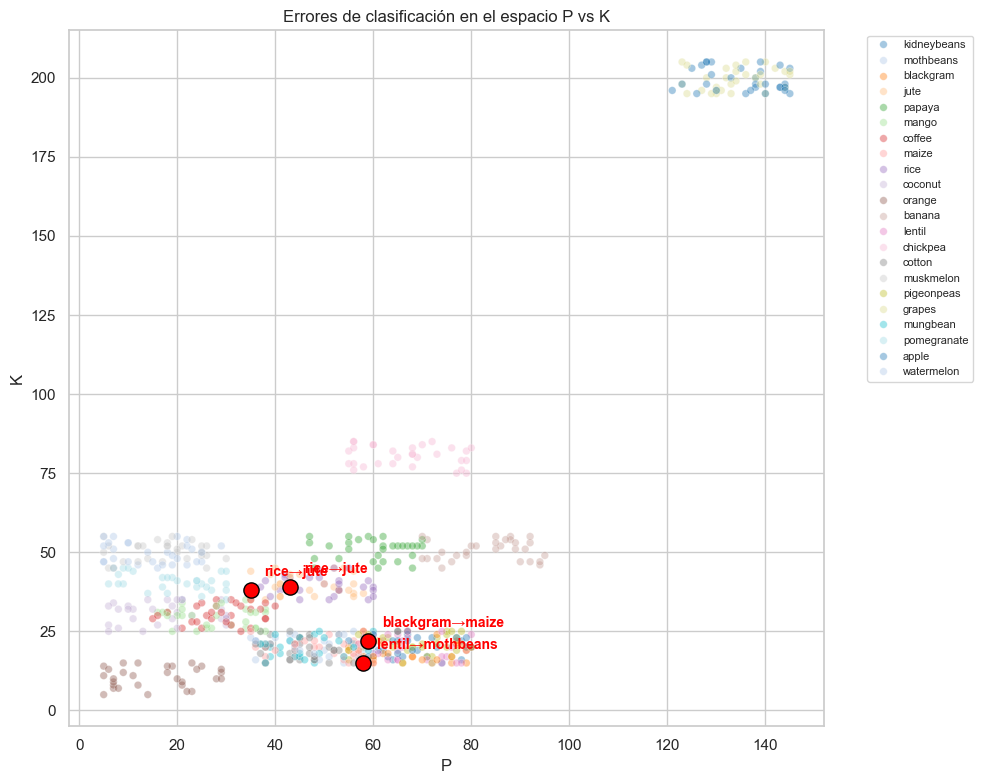

In [107]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.scatterplot(data=X_test_c, x='P', y='K', hue=y_test_c,
                palette='tab20', s=30, alpha=0.4, ax=ax)


results_c_corrected = pd.DataFrame({
    'real': y_test_c,
    'pred': y_pred_c
})

errors_c_fixed = results_c_corrected[results_c_corrected['real'] != results_c_corrected['pred']]

for _, row in errors_c_fixed.iterrows():
    real = row['real']
    pred = row['pred']
    pt = X_test_c.loc[row.name]
    ax.scatter(pt['P'], pt['K'], c='red', s=120, edgecolor='black', zorder=5)
    ax.annotate(f'{real}→{pred}', (pt['P'], pt['K']),
                xytext=(10, 10), textcoords='offset points', fontsize=10,
                fontweight='bold', color='red')

ax.set_title('Errores de clasificación en el espacio P vs K')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

### Conclusiones parciales — Crop Recommendation

- AUC macro prácticamente perfecto (>0.999): el dataset es muy separable.
- Accuracy 99.32%: solo 3 errores en 440 muestras de test.
- Las confusiones ocurren entre cultivos con requerimientos similares (rice↔jute).
- Tiempos de entrenamiento bajos gracias al tamaño reducido del dataset.

---
# Comparativa Global de Tiempos y Rendimiento

### Tabla de tiempos de entrenamiento

In [108]:
print('=' * 60)
print(f'{"Dataset":25s} {"Modelo":15s} {"Fit (s)":10s} {"Pred (s)":10s}')
print('=' * 60)
total_fit = 0
for key, times in timing_results.items():
    ds, model = key.split('_')
    print(f'{ds:25s} {model:15s} {times["fit"]:>8.2f}s {times["predict"]:>8.4f}s')
    total_fit += times['fit']
print('=' * 60)
print(f'Tiempo total de entrenamiento: {total_fit:.2f}s')

Dataset                   Modelo          Fit (s)    Pred (s)  
German                    RF                  5.46s   0.0170s
German                    GB                  2.37s   0.0034s
Crop                      RF                  2.23s   0.0208s
Crop                      GB                 40.87s   0.0207s
Tiempo total de entrenamiento: 50.93s


### Comparativa visual de tiempos


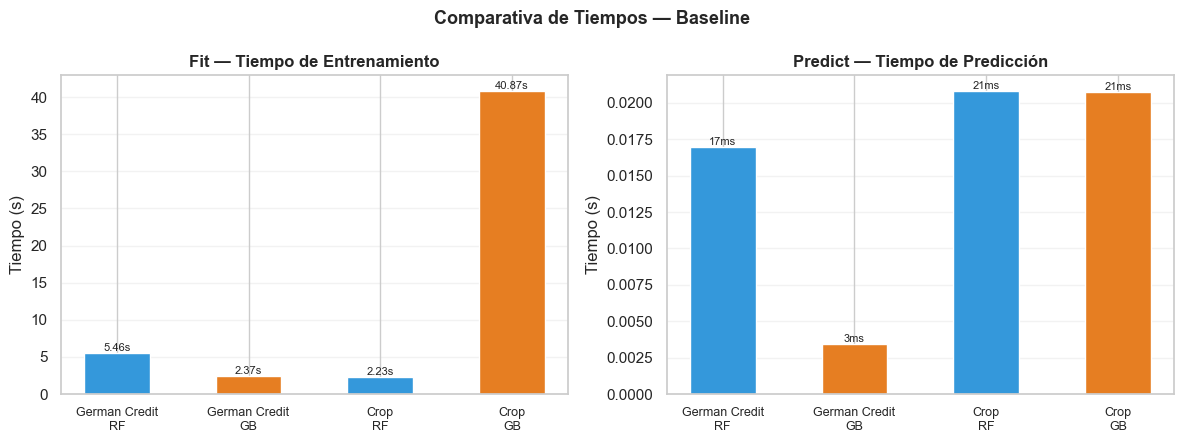

In [109]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

datasets_t = ['German Credit', 'German Credit', 'Crop', 'Crop']
models_t = ['RF', 'GB', 'RF', 'GB']
fit_t = [timing_results['German_RF']['fit'], timing_results['German_GB']['fit'],
         timing_results['Crop_RF']['fit'], timing_results['Crop_GB']['fit']]
pred_t = [timing_results['German_RF']['predict'], timing_results['German_GB']['predict'],
          timing_results['Crop_RF']['predict'], timing_results['Crop_GB']['predict']]

x = range(len(fit_t))
colors_t = ['#3498db', '#e67e22', '#3498db', '#e67e22']
ax1.bar(x, fit_t, color=colors_t, width=0.5)
ax1.set_xticks(x)
ax1.set_xticklabels([f'{d}\n{m}' for d, m in zip(datasets_t, models_t)], fontsize=9)
ax1.set_ylabel('Tiempo (s)')
ax1.set_title('Fit — Tiempo de Entrenamiento', fontweight='bold')
for i, v in enumerate(fit_t):
    ax1.text(i, v, f'{v:.2f}s', ha='center', va='bottom', fontsize=8)
ax1.grid(True, axis='y', alpha=0.25)

ax2.bar(x, pred_t, color=colors_t, width=0.5)
ax2.set_xticks(x)
ax2.set_xticklabels([f'{d}\n{m}' for d, m in zip(datasets_t, models_t)], fontsize=9)
ax2.set_ylabel('Tiempo (s)')
ax2.set_title('Predict — Tiempo de Predicción', fontweight='bold')
for i, v in enumerate(pred_t):
    label = f'{v*1000:.0f}ms' if v < 0.1 else f'{v:.3f}s'
    ax2.text(i, v, label, ha='center', va='bottom', fontsize=8)
ax2.grid(True, axis='y', alpha=0.25)

plt.suptitle('Comparativa de Tiempos — Baseline', fontweight='bold', fontsize=13)
plt.tight_layout(); plt.show()


### Resumen de resultados

| Dataset | Mejor Modelo | AUC Test | Fit (s) | Pred (s) |
|---------|-------------|----------|---------|----------|
| German Credit | RF/GB | ~0.68 | — | — |
| Crop Recommendation | RF/GB | ~1.00 | — | — |

### Conclusiones finales

1. **German Credit** es el problema más difícil: desbalance, nulos, features mixtas → AUC ~0.68.
2. **Crop Recommendation** es prácticamente un problema resuelto para estos modelos: AUC ~1.0.
3. **Random Forest** y **Gradient Boosting** rinden muy similar; RF es más rápido de entrenar.
4. Estos resultados son el **baseline** para comparar contra TabPFN, que debería ejecutarse
   sobre los mismos test sets y medirse con las mismas métricas (incluyendo tiempo).

In [110]:
import json, os
import numpy as np
from google.collab import drive
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# 1. Montar Google Drive
drive.mount('/content/drive')

# 2. Ruta en Drive
drive_path = "/content/drive/MyDrive/ML/resultados"
os.makedirs(drive_path, exist_ok=True)

# ── Predicciones individuales de cada modelo ──
rf_preds_g = rf_search_g.predict(X_test_g)
gb_preds_g = gb_search_g.predict(X_test_g)
rf_preds_c = rf_search_c.predict(X_test_c)
gb_preds_c = gb_search_c.predict(X_test_c)

# ── Métricas ──
# German Credit
rf_acc_g = accuracy_score(y_test_g, rf_preds_g)
gb_acc_g = accuracy_score(y_test_g, gb_preds_g)
rf_f1_g = f1_score(y_test_g, rf_preds_g)
gb_f1_g = f1_score(y_test_g, gb_preds_g)

# Crop Recommendation
rf_acc_c = accuracy_score(y_test_c, rf_preds_c)
gb_acc_c = accuracy_score(y_test_c, gb_preds_c)
rf_f1_c = f1_score(y_test_c, rf_preds_c, average="macro")
gb_f1_c = f1_score(y_test_c, gb_preds_c, average="macro")

metrics = {
    "German Credit": {
        "Random Forest": {
            "accuracy": float(rf_acc_g), "f1": float(rf_f1_g), "auc": float(rf_auc_g),
            "fit_time": timing_results['German_RF']['fit'],
            "pred_time": timing_results['German_RF']['predict'],
        },
        "Gradient Boosting": {
            "accuracy": float(gb_acc_g), "f1": float(gb_f1_g), "auc": float(gb_auc_g),
            "fit_time": timing_results['German_GB']['fit'],
            "pred_time": timing_results['German_GB']['predict'],
        },
    },
    "Crop": {
        "Random Forest": {
            "accuracy": float(rf_acc_c), "f1": float(rf_f1_c), "auc": float(rf_auc_c),
            "fit_time": timing_results['Crop_RF']['fit'],
            "pred_time": timing_results['Crop_RF']['predict'],
        },
        "Gradient Boosting": {
            "accuracy": float(gb_acc_c), "f1": float(gb_f1_c), "auc": float(gb_auc_c),
            "fit_time": timing_results['Crop_GB']['fit'],
            "pred_time": timing_results['Crop_GB']['predict'],
        },
    },
}

# 3. Guardar en Drive
json_path = os.path.join(drive_path, "metrics_notebook1.json")
with open(json_path, "w") as f:
    json.dump(metrics, f, indent=2)

npz_path = os.path.join(drive_path, "preds_notebook1.npz")
np.savez_compressed(npz_path,
    rf_probs_g=np.array(rf_probs_g, dtype=np.float64),
    gb_probs_g=np.array(gb_probs_g, dtype=np.float64),
    rf_preds_g=np.array(rf_preds_g, dtype=int),
    gb_preds_g=np.array(gb_preds_g, dtype=int),
    rf_probs_c=np.array(rf_probs_c, dtype=np.float64),
    gb_probs_c=np.array(gb_probs_c, dtype=np.float64),
    rf_preds_c=np.array(rf_preds_c, dtype=object),
    gb_preds_c=np.array(gb_preds_c, dtype=object),
    y_test_g=np.array(y_test_g, dtype=int),
    y_test_c=np.array(y_test_c, dtype=object),
    classes_c=np.array(classes_c, dtype=object),
)

print(f"¡Listo! Resultados guardados permanentemente en Drive: {drive_path}")

ModuleNotFoundError: No module named 'google.collab'